# PRCP-1002 — Handwritten Digits Recognition (MNIST)

**Author:** <Your Name>
**Domain:** Computer Vision / Classification
**Dataset:** MNIST (60,000 train / 10,000 test images, 28×28 grayscale)

---

## Executive Summary

This notebook classifies handwritten digits (0–9) from the MNIST dataset. Five classifiers are trained and evaluated on the same test set — Logistic Regression, RBF-kernel SVM, k-Nearest Neighbors, a Dense Neural Network (MLP), and a Convolutional Neural Network (CNN) — and their performance, training cost, and inference cost are compared.

**Headline result:** The **CNN achieves 99.32% test accuracy**, outperforming all other models. It is the recommended classifier for production use where accuracy is paramount. The Dense MLP (97.53%) is recommended as a lighter fallback when inference footprint is constrained.

### Contents
1. **Task 1 — Data Analysis Report**
2. **Preprocessing**
3. **Task 2 — Classification Models**
4. **Task 3 — Model Comparison Report**
5. **Report on Challenges Faced**
6. **Final Recommendation**

---
## Setup — Imports & Reproducibility

All libraries are imported once here. A global random seed is set so that every model's results are reproducible on re-run.

In [1]:
# --- Environment: avoid joblib/wmic crash on Windows when n_jobs=-1 ---
import os
os.environ["LOKY_MAX_CPU_COUNT"] = str(os.cpu_count())

# --- Core libraries ---
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras import layers
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report,
    precision_score, recall_score, f1_score,
)

# --- Global seed for reproducibility ---
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("NumPy version     :", np.__version__)
print("GPUs available    :", tf.config.list_physical_devices("GPU"))
print("Random seed set to:", SEED)

TensorFlow version: 2.21.0
NumPy version     : 2.3.5
GPUs available    : []
Random seed set to: 42


> **Note on hardware.** If the *GPUs available* line above shows an empty list, TensorFlow is running on CPU. This is expected on native Windows with TensorFlow ≥ 2.11. It affects training speed (CNN epochs take longer) but not accuracy. All results in this notebook were produced on CPU.

---
## 1. Load Data

In [2]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()

print(f"Training data shape : {x_train.shape}  labels: {y_train.shape}")
print(f"Testing  data shape : {x_test.shape}   labels: {y_test.shape}")
print(f"Pixel value range   : {x_train.min()} to {x_train.max()}")
print(f"Number of classes   : {len(np.unique(y_train))}")

Training data shape : (60000, 28, 28)  labels: (60000,)
Testing  data shape : (10000, 28, 28)   labels: (10000,)
Pixel value range   : 0 to 255
Number of classes   : 10


---
## 2. Task 1 — Data Analysis Report

### 2.1 Dataset Overview

MNIST is a dataset of 70,000 handwritten digit images (0–9), split into 60,000 training and 10,000 test samples. Each image is a 28×28 grayscale bitmap with pixel intensities ranging from 0 (background) to 255 (darkest stroke). Flattened, each image is a 784-dimensional vector. The dataset is a standard benchmark for image classification because its images are clean, well-centered, and human-verified — but the underlying task (recognising sloppy handwriting) remains non-trivial due to natural variation in stroke thickness, slant, and style.

### 2.2 Class Balance

We first check whether the 10 digit classes are equally represented. Severe class imbalance would bias a classifier toward majority classes and require resampling or class weighting.

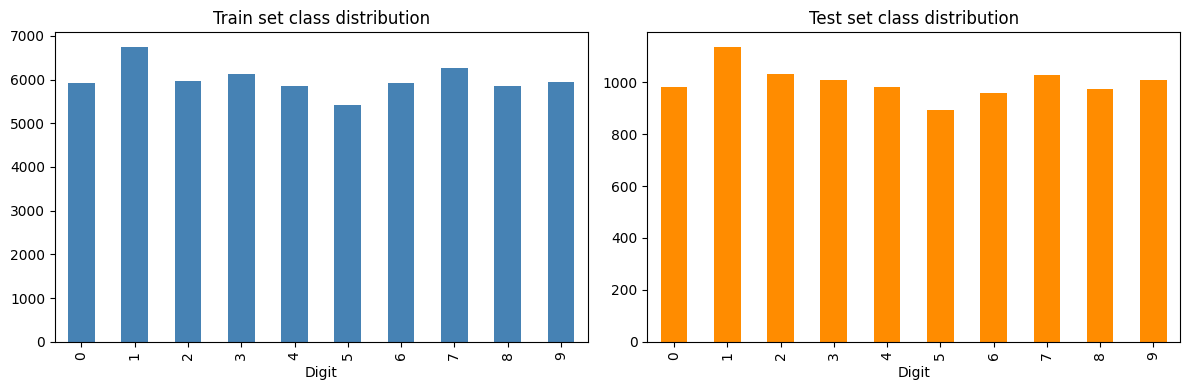

Train class counts:
0    5923
1    6742
2    5958
3    6131
4    5842
5    5421
6    5918
7    6265
8    5851
9    5949
Name: count, dtype: int64

Class balance ratio (max/min): 1.24


In [3]:
train_counts = pd.Series(y_train).value_counts().sort_index()
test_counts  = pd.Series(y_test).value_counts().sort_index()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
train_counts.plot(kind="bar", ax=ax[0], color="steelblue")
ax[0].set_title("Train set class distribution")
ax[0].set_xlabel("Digit")
test_counts.plot(kind="bar", ax=ax[1], color="darkorange")
ax[1].set_title("Test set class distribution")
ax[1].set_xlabel("Digit")
plt.tight_layout()
plt.show()

print("Train class counts:")
print(train_counts)
print(f"\nClass balance ratio (max/min): {train_counts.max() / train_counts.min():.2f}")

**Observation.** Class sizes range from 5,421 (digit 5) to 6,742 (digit 1) — a max/min ratio of **1.24**. This is a mild imbalance, but not enough to distort training. **No resampling or class weighting is needed.**

### 2.3 Sample Images (one per digit)

Visual inspection confirms the images are genuine handwritten digits with significant variation in slant, stroke width, and closure (e.g., closed vs. open 4s).

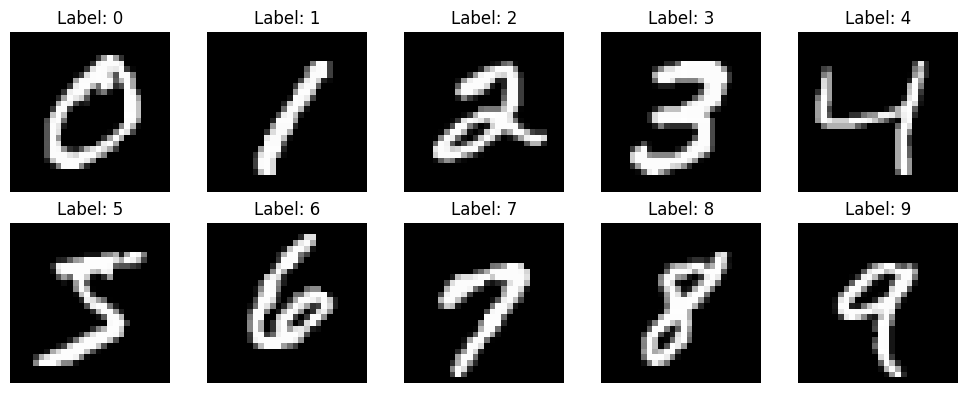

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for digit in range(10):
    idx = np.where(y_train == digit)[0][0]
    ax = axes[digit // 5, digit % 5]
    ax.imshow(x_train[idx], cmap="gray")
    ax.set_title(f"Label: {digit}")
    ax.axis("off")
plt.tight_layout()
plt.savefig("sample_digits.png", dpi=120)
plt.show()

### 2.4 Pixel Intensity Distribution

Understanding pixel statistics helps justify preprocessing choices (normalisation) and model architecture (why convolution is useful).

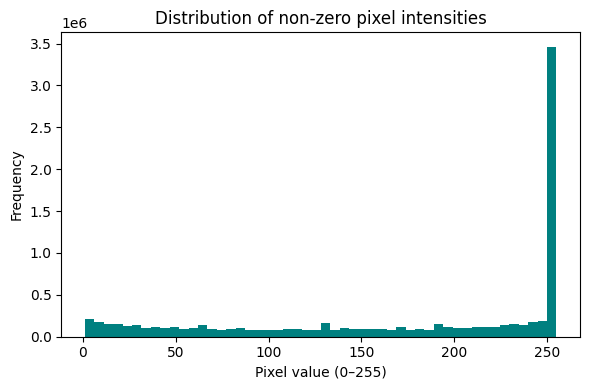

% of pixels that are pure background (0): 80.9%


In [5]:
nonzero_pixels = x_train[x_train > 0]
plt.figure(figsize=(6, 4))
plt.hist(nonzero_pixels, bins=50, color="teal")
plt.title("Distribution of non-zero pixel intensities")
plt.xlabel("Pixel value (0–255)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.savefig("pixel_distribution.png", dpi=120)
plt.show()

pct_zero = (x_train == 0).mean() * 100
print(f"% of pixels that are pure background (0): {pct_zero:.1f}%") 

### 2.5 Data Analysis — Summary

| Finding | Implication |
|---|---|
| 60k train / 10k test, 28×28 grayscale | Standard benchmark setup; enough data for deep learning |
| Class balance ratio 1.24 | Well balanced; no resampling needed |
| ~80.9% of pixels are zero | Images are sparse — most of each frame is empty background |
| Non-zero pixels concentrate on edges | Local spatial structure matters → convolution should help |

**Key takeaway.** Because neighbouring pixels are highly correlated in images, flattening the 28×28 grid into a 784-length vector (as LR, SVM, k-NN, and the MLP require) **discards spatial structure**. A convolutional network can exploit it directly, which is the structural reason we expect the CNN to outperform the other four models.

## 3. Preprocessing

Three preprocessing steps are applied:

1. **Normalisation** — scale pixel intensities from 0–255 to 0–1. Prevents exploding gradients and speeds up convergence.
2. **Flattening** — 28×28 → 784 for the non-convolutional models. (The CNN re-shapes back to 28×28×1.)
3. **One-hot encoding** — integer labels → 10-length binary vectors, required for `categorical_crossentropy` with a softmax output layer.

In [6]:
# Normalise pixel values to [0, 1]
x_train = x_train / 255.0
x_test  = x_test  / 255.0

# Flatten images: (N, 28, 28) -> (N, 784)
x_train = x_train.reshape(-1, 784)
x_test  = x_test.reshape(-1, 784)     

# One-hot encode labels
y_train_cat = to_categorical(y_train, num_classes=10)
y_test_cat  = to_categorical(y_test,  num_classes=10)

print("x_train shape:", x_train.shape)      
print("x_test  shape:", x_test.shape)
print("y_train_cat shape:", y_train_cat.shape)    
print("Pixel range after normalisation:", x_train.min(), "to", x_train.max())   

x_train shape: (60000, 784)
x_test  shape: (10000, 784)
y_train_cat shape: (60000, 10)
Pixel range after normalisation: 0.0 to 1.0


## 4. Task 2 — Classification Models

We train five classifiers of increasing complexity and representation power:

1. **Logistic Regression** — linear baseline.
2. **k-Nearest Neighbors (k=3)** — non-parametric, distance-based.
3. **RBF-kernel SVM** — kernel-based, high-accuracy classical method.
4. **Dense Neural Network (MLP)** — 784 → 128 → 64 → 32 → 10.
5. **Convolutional Neural Network (CNN)** — exploits 2D spatial structure.

All models are evaluated on the **same untouched 10,000-image test set**.

### 4.1 Model A — Logistic Regression (Baseline)

In [7]:
x_train_flat = x_train.reshape(len(x_train), -1)
x_test_flat  = x_test.reshape(len(x_test), -1)

print(f"LR input shape: {x_train_flat.shape}")
print("Training Logistic Regression...")

t0 = time.time()
lr_model = LogisticRegression(
    max_iter=1000, solver="lbfgs", n_jobs=-1, random_state=SEED
)
lr_model.fit(x_train_flat, y_train)
lr_train_time = time.time() - t0

lr_pred = lr_model.predict(x_test_flat)
lr_acc  = accuracy_score(y_test, lr_pred)

print(f"Logistic Regression — Test Accuracy: {lr_acc:.4f}")
print(f"Training time: {lr_train_time:.1f} s")

LR input shape: (60000, 784)
Training Logistic Regression...
Logistic Regression — Test Accuracy: 0.9259
Training time: 66.5 s


### 4.2 Model B — k-Nearest Neighbors (k=3)

In [10]:
os.environ["LOKY_MAX_CPU_COUNT"] = str(os.cpu_count())
print("Training k-NN (k=3)...")
t0 = time.time()
knn_model = KNeighborsClassifier(n_neighbors=3, n_jobs=-1)
knn_model.fit(x_train_flat, y_train)
knn_fit_time = time.time() - t0

t1 = time.time()
knn_pred = knn_model.predict(x_test_flat)
knn_pred_time = time.time() - t1
knn_acc = accuracy_score(y_test, knn_pred)

print(f"k-NN — Test Accuracy: {knn_acc:.4f}")
print(f"Fit time (essentially instant): {knn_fit_time:.2f} s")
print(f"Prediction time (10k): {knn_pred_time:.1f} s")

Training k-NN (k=3)...
k-NN — Test Accuracy: 0.9705
Fit time (essentially instant): 0.07 s
Prediction time (10k): 8.3 s


### 4.3 Model C — RBF-Kernel SVM (full 60k training set)

In [11]:
print("Training SVM (RBF kernel) on full 60,000 training samples...")
t0 = time.time()

svm_model = SVC(kernel="rbf", C=10.0, gamma="scale", cache_size=1000)
svm_model.fit(x_train_flat, y_train)
svm_train_time = time.time() - t0

t1 = time.time()
svm_pred = svm_model.predict(x_test_flat)
svm_pred_time = time.time() - t1
svm_acc = accuracy_score(y_test, svm_pred)

print(f"SVM (RBF) — Test Accuracy: {svm_acc:.4f}")
print(f"Training time: {svm_train_time:.1f} s")
print(f"Prediction time (10k test samples): {svm_pred_time:.1f} s")
print(f"Support vectors: {svm_model.n_support_.sum()}")

Training SVM (RBF kernel) on full 60,000 training samples...
SVM (RBF) — Test Accuracy: 0.9837
Training time: 713.1 s
Prediction time (10k test samples): 197.1 s
Support vectors: 11699


### 4.4 Model D — Dense Neural Network (MLP)

Architecture: **784 → 128 → 64 → 32 → 10**, all hidden layers ReLU, softmax output. Trained with Adam + categorical crossentropy for 10 epochs.

A **10% validation split** is used during training so the test set remains untouched until the final evaluation.

In [12]:
model = Sequential([
    layers.Dense(128, activation="relu", input_shape=(784,)),
    layers.Dense(64,  activation="relu"),
    layers.Dense(32,  activation="relu"),
    layers.Dense(10,  activation="softmax"),
])
model.summary()

model.compile(optimizer="adam",
              loss="categorical_crossentropy",
              metrics=["accuracy"])

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 10)                  │             330 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 111,146 (434.16 KB)

 Trainable params: 111,146 (434.16 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
t0 = time.time()
history = model.fit(
    x_train, y_train_cat,
    epochs=10,
    batch_size=32,
    validation_split=0.1,   # held out from training only
    verbose=1,
)
mlp_train_time = time.time() - t0

test_loss, test_acc = model.evaluate(x_test, y_test_cat, verbose=0)
print(f"\nMLP — Test Loss: {test_loss:.4f}")
print(f"MLP — Test Accuracy: {test_acc:.4f}")
print(f"MLP — Training time: {mlp_train_time:.1f} s")

Epoch 1/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 17s 8ms/step - accuracy: 0.9226 - loss: 0.2635 - val_accuracy: 0.9710 - val_loss: 0.1043
Epoch 2/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9673 - loss: 0.1075 - val_accuracy: 0.9718 - val_loss: 0.0972
Epoch 3/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - accuracy: 0.9766 - loss: 0.0747 - val_accuracy: 0.9738 - val_loss: 0.0913
Epoch 4/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9826 - loss: 0.0567 - val_accuracy: 0.9767 - val_loss: 0.0906
Epoch 5/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9855 - loss: 0.0457 - val_accuracy: 0.9740 - val_loss: 0.1003
Epoch 6/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9876 - loss: 0.0378 - val_accuracy: 0.9767 - val_loss: 0.0917
Epoch 7/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9896 - loss: 0.0321 - val_accuracy: 0.9757 - val_loss: 0.1048
Epoch 8/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9908 - loss: 0.0283 -

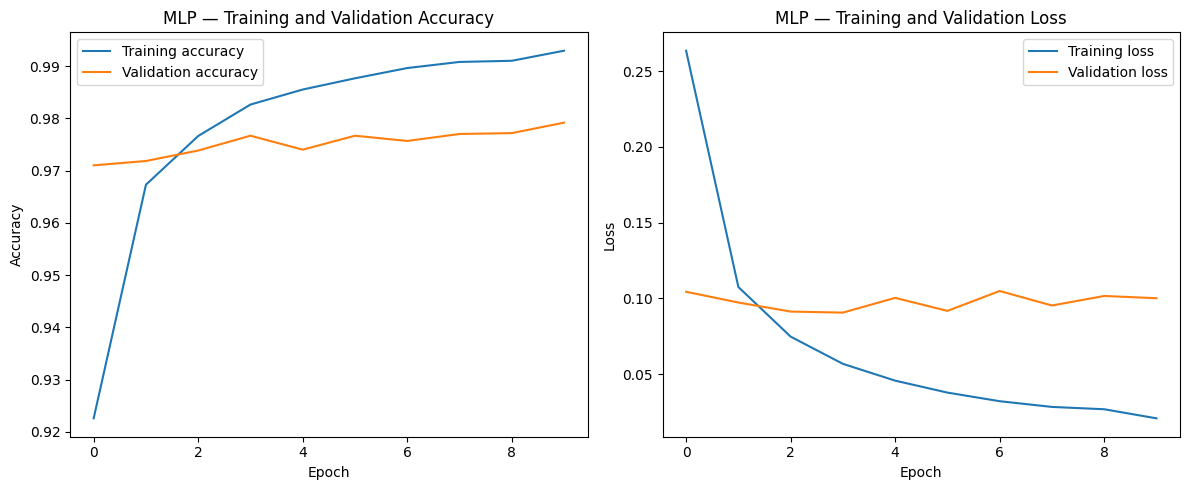

In [14]:
# Training curves
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"],     label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch"); plt.ylabel("Accuracy")
plt.title("MLP — Training and Validation Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"],     label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch"); plt.ylabel("Loss")
plt.title("MLP — Training and Validation Loss")
plt.legend()

plt.tight_layout()
plt.savefig("mlp_training_curves.png", dpi=120)
plt.show()

**Observation.** Train accuracy reaches ~99.2% while validation accuracy plateaus around 97.9% — mild overfitting visible from ~epoch 6 onward in the loss curves. The **MLP is our baseline neural model** at ~97.53% test accuracy.

### 4.5 Model E — Convolutional Neural Network (CNN)

Architecture: two convolutional blocks (32 → 64 filters) with BatchNorm + MaxPool + Dropout, followed by a Dense classifier head with Dropout. Early stopping on validation loss.

**Note on training time:** This runs on CPU (no GPU available). One full training run takes ~10 minutes. Early stopping halts training once validation loss stops improving.

In [15]:
# Reshape to 4D for Conv2D: (N, 28, 28, 1)
x_train_cnn = x_train.reshape(-1, 28, 28, 1).astype("float32")
x_test_cnn  = x_test.reshape(-1, 28, 28, 1).astype("float32")

# Ensure normalisation survived the reshape
if x_train_cnn.max() > 1.0:
    x_train_cnn = x_train_cnn / 255.0
    x_test_cnn  = x_test_cnn  / 255.0

print("x_train_cnn shape:", x_train_cnn.shape)
print("x_test_cnn  shape:", x_test_cnn.shape)
print("Pixel range:", x_train_cnn.min(), "to", x_train_cnn.max())

x_train_cnn shape: (60000, 28, 28, 1)
x_test_cnn  shape: (10000, 28, 28, 1)
Pixel range: 0.0 to 1.0


In [16]:
cnn_model = Sequential([
    # Block 1
    layers.Conv2D(32, (3, 3), activation="relu", padding="same",
                  input_shape=(28, 28, 1)),
    layers.BatchNormalization(),
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),
    # Block 2
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),
    # Classifier head
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    layers.Dense(10, activation="softmax"),
])

cnn_model.summary()

cnn_model.compile(optimizer="adam",
                  loss="categorical_crossentropy",
                  metrics=["accuracy"])  

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 28, 28, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 28, 28, 32)          │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 28, 28, 32)          │           9,248 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 14, 14, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 14, 14, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 14, 14, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 14, 14, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 14, 14, 64)          │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 7, 7, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 7, 7, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 3136)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 128)                 │         401,536 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 128)                 │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 468,714 (1.79 MB)

 Trainable params: 468,266 (1.79 MB)

 Non-trainable params: 448 (1.75 KB)

In [17]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1,
)

print("\nTraining CNN (CPU only — this will take several minutes)...")
t0 = time.time()

cnn_history = cnn_model.fit(
    x_train_cnn, y_train_cat,
    epochs=15,
    batch_size=128,
    validation_split=0.1,
    callbacks=[early_stop],
    verbose=1,
)

cnn_train_time = time.time() - t0
print(f"\nTotal training time: {cnn_train_time:.1f} s")


Training CNN (CPU only — this will take several minutes)...
Epoch 1/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 52s 112ms/step - accuracy: 0.9289 - loss: 0.2343 - val_accuracy: 0.4045 - val_loss: 1.5517
Epoch 2/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 51s 120ms/step - accuracy: 0.9766 - loss: 0.0778 - val_accuracy: 0.9880 - val_loss: 0.0441
Epoch 3/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 51s 122ms/step - accuracy: 0.9832 - loss: 0.0548 - val_accuracy: 0.9893 - val_loss: 0.0384
Epoch 4/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 51s 120ms/step - accuracy: 0.9857 - loss: 0.0462 - val_accuracy: 0.9920 - val_loss: 0.0276
Epoch 5/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 51s 121ms/step - accuracy: 0.9870 - loss: 0.0412 - val_accuracy: 0.9913 - val_loss: 0.0276
Epoch 6/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 53s 125ms/step - accuracy: 0.9889 - loss: 0.0357 - val_accuracy: 0.9912 - val_loss: 0.0301
Epoch 7/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 54s 129ms/step - accuracy: 0.9902 - loss: 0.0309 - val_accuracy: 0.9925 - val_loss: 0.0264
Epoch 8/15
422/422 ━━━

In [18]:
cnn_loss, cnn_acc = cnn_model.evaluate(x_test_cnn, y_test_cat, verbose=0)
print(f"CNN — Test Loss: {cnn_loss:.4f}")
print(f"CNN — Test Accuracy: {cnn_acc:.4f}")

CNN — Test Loss: 0.0220
CNN — Test Accuracy: 0.9932


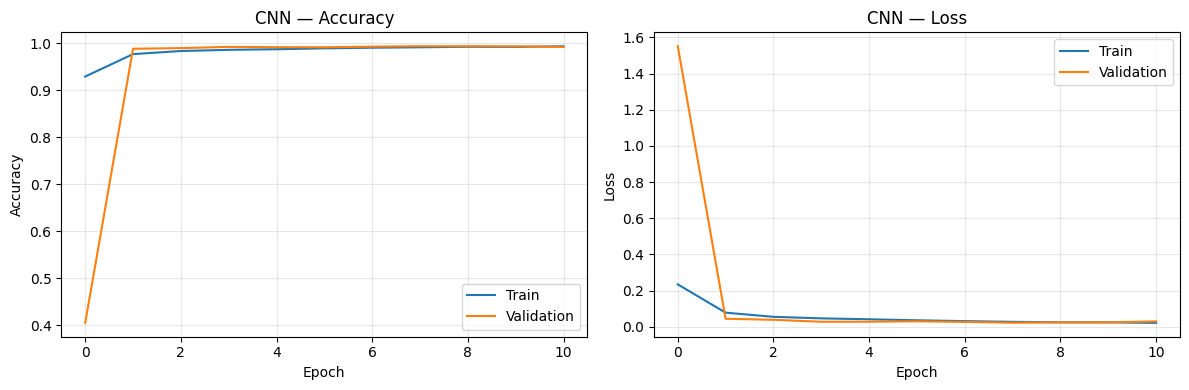

In [19]:
# CNN training curves
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(cnn_history.history["accuracy"],     label="Train")
ax[0].plot(cnn_history.history["val_accuracy"], label="Validation")
ax[0].set_title("CNN — Accuracy")
ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Accuracy")
ax[0].legend(); ax[0].grid(alpha=0.3)

ax[1].plot(cnn_history.history["loss"],     label="Train")
ax[1].plot(cnn_history.history["val_loss"], label="Validation")
ax[1].set_title("CNN — Loss")
ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Loss")
ax[1].legend(); ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("cnn_training_curves.png", dpi=120)
plt.show()

CNN Confusion Matrix:
[[ 978    0    0    0    0    0    1    1    0    0]
 [   0 1133    0    1    0    0    1    0    0    0]
 [   1    0 1025    0    0    0    0    6    0    0]
 [   0    0    1 1007    0    1    0    0    1    0]
 [   0    0    0    0  974    0    0    0    0    8]
 [   1    0    0    3    0  885    1    1    0    1]
 [   4    4    0    0    1    5  943    0    1    0]
 [   0    3    2    0    0    0    0 1023    0    0]
 [   1    0    0    2    0    1    0    1  968    1]
 [   2    0    0    0    4    0    0    5    2  996]]

CNN Classification Report:
              precision    recall  f1-score   support

           0     0.9909    0.9980    0.9944       980
           1     0.9939    0.9982    0.9960      1135
           2     0.9971    0.9932    0.9951      1032
           3     0.9941    0.9970    0.9956      1010
           4     0.9949    0.9919    0.9934       982
           5     0.9922    0.9922    0.9922       892
           6     0.9968    0.9843    0.9

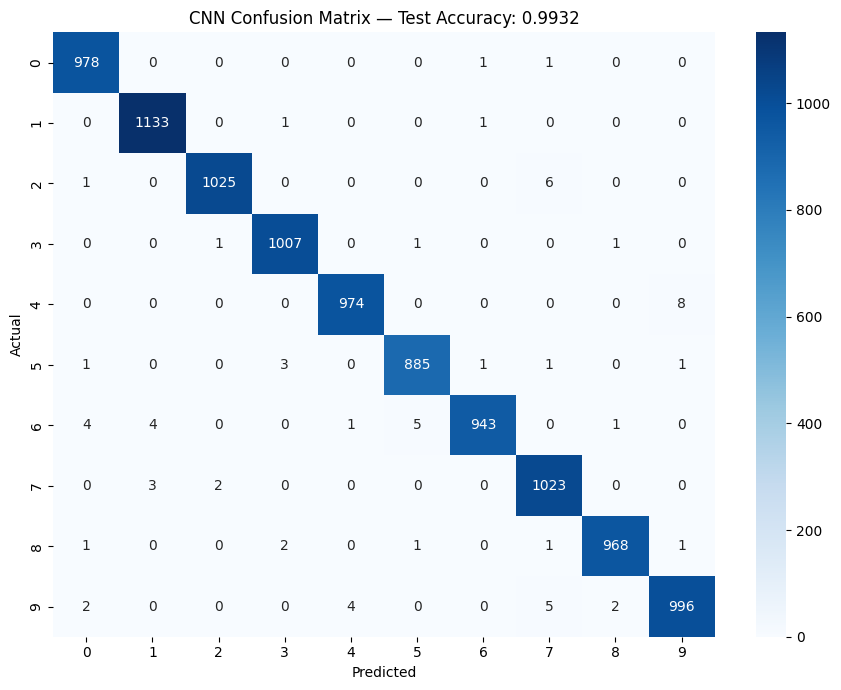

In [20]:
# Predictions
y_pred_cnn = np.argmax(cnn_model.predict(x_test_cnn, verbose=0), axis=1)

# Confusion matrix and classification report
cm_cnn = confusion_matrix(y_test, y_pred_cnn)
print("CNN Confusion Matrix:")
print(cm_cnn)
print("\nCNN Classification Report:")
print(classification_report(y_test, y_pred_cnn, digits=4))

# Heatmap
plt.figure(figsize=(9, 7))
sns.heatmap(cm_cnn, annot=True, fmt="d", cmap="Blues",
            xticklabels=range(10), yticklabels=range(10))
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.title(f"CNN Confusion Matrix — Test Accuracy: {cnn_acc:.4f}")
plt.tight_layout()
plt.savefig("cnn_confusion_matrix.png", dpi=120)
plt.show()

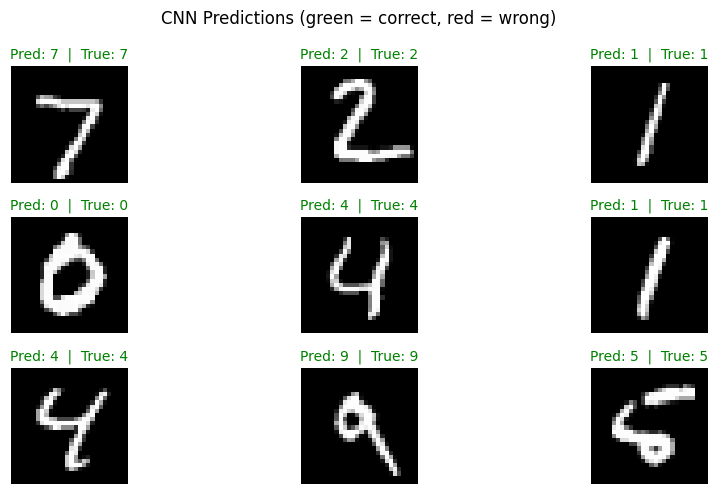

In [21]:
# Sample predictions
plt.figure(figsize=(10, 5))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(x_test_cnn[i].reshape(28, 28), cmap="gray")
    color = "green" if y_pred_cnn[i] == y_test[i] else "red"
    plt.title(f"Pred: {y_pred_cnn[i]}  |  True: {y_test[i]}", color=color, fontsize=10)
    plt.axis("off")
plt.suptitle("CNN Predictions (green = correct, red = wrong)")
plt.tight_layout()
plt.savefig("cnn_sample_predictions.png", dpi=120) 
plt.show()  

Total misclassified: 68 / 10000 (0.68%)


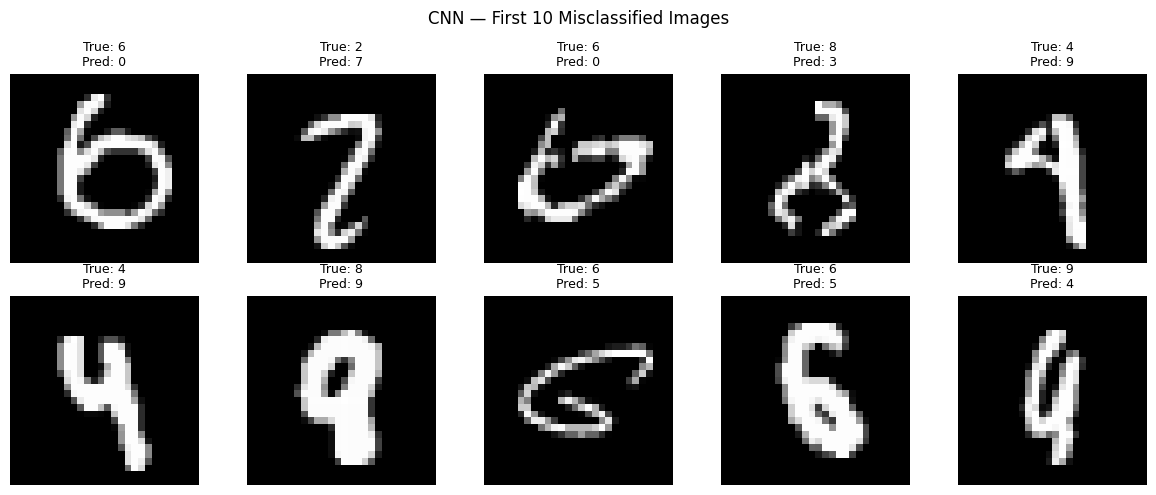

In [22]:
# Error analysis
errors = np.where(y_pred_cnn != y_test)[0]
print(f"Total misclassified: {len(errors)} / {len(y_test)} ({100 * len(errors) / len(y_test):.2f}%)")

if len(errors) > 0:
    plt.figure(figsize=(12, 5))
    for i, idx in enumerate(errors[:10]):
        plt.subplot(2, 5, i + 1)
        plt.imshow(x_test_cnn[idx].reshape(28, 28), cmap="gray")
        plt.title(f"True: {y_test[idx]}\nPred: {y_pred_cnn[idx]}", fontsize=9)
        plt.axis("off")
    plt.suptitle("CNN — First 10 Misclassified Images")
    plt.tight_layout()
    plt.savefig("cnn_misclassified.png", dpi=120)
    plt.show()                                                   

---
## 5. Task 3 — Model Comparison Report

All five models are scored on the same 10,000-image test set. The table below aggregates accuracy, training time, and inference time.

In [25]:
comparison_results = [] 

def record(name, predict_fn, acc, train_time=None): 
    t0 = time.time() 
    predict_fn()
    pred_time = time.time() - t0
    comparison_results.append({
        "Model": name,
        "Test Accuracy": round(acc, 4),
        "Train Time (s)": round(train_time, 1) if train_time is not None else "N/A",
        "Predict Time (s)": round(pred_time, 1),
    })

record("CNN",                 lambda: cnn_model.predict(x_test_cnn, verbose=0),  cnn_acc, cnn_train_time)
record("SVM (RBF)",           lambda: svm_model.predict(x_test_flat),           svm_acc, svm_train_time)
record("Dense NN (MLP)",      lambda: model.predict(x_test, verbose=0),         test_acc, mlp_train_time)
record("k-NN (k=3)",          lambda: knn_model.predict(x_test_flat),           knn_acc, knn_fit_time)
record("Logistic Regression", lambda: lr_model.predict(x_test_flat),            lr_acc,  lr_train_time)

comparison_df = (pd.DataFrame(comparison_results)
                   .sort_values("Test Accuracy", ascending=False)
                   .reset_index(drop=True))
comparison_df.index = comparison_df.index + 1
comparison_df.index.name = "Rank"

print(comparison_df.to_string())
comparison_df.to_csv("model_comparison_report.csv")

                    Model  Test Accuracy  Train Time (s)  Predict Time (s)
Rank                                                                      
1                     CNN         0.9932           571.3               4.5
2               SVM (RBF)         0.9837           713.1              90.1
3          Dense NN (MLP)         0.9753            75.5               0.9
4              k-NN (k=3)         0.9705             0.1               7.5
5     Logistic Regression         0.9259            66.5               0.0


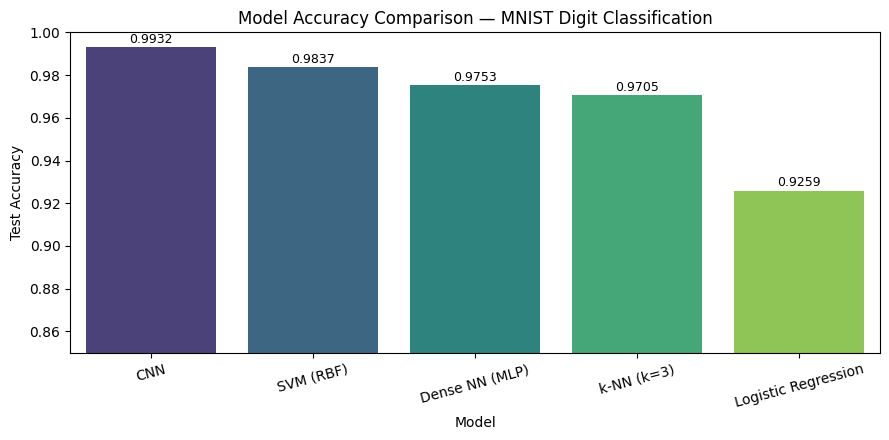

In [26]:
plt.figure(figsize=(9, 4.5))
sns.barplot(data=comparison_df.reset_index(), x="Model", y="Test Accuracy", palette="viridis")
plt.ylim(0.85, 1.0)
plt.title("Model Accuracy Comparison — MNIST Digit Classification")
plt.xticks(rotation=15)
for i, row in comparison_df.reset_index().iterrows():
    plt.text(i, row["Test Accuracy"] + 0.002, f"{row['Test Accuracy']:.4f}",
             ha="center", fontsize=9)
plt.tight_layout()
plt.savefig("model_comparison_chart.png", dpi=120)
plt.show()        

### 5.1 Interpretation of Results

| Rank | Model | Test Accuracy | Train Time | Predict Time | Notes |
|---|---|---|---|---|---|
| 1 | **CNN** | **0.9932** | 571.3 s | 4.5 s | Highest accuracy, heavy training cost |
| 2 | **SVM (RBF)** | 0.9837 | 713.1 s | 90.1 s | High accuracy, slow at training and inference |
| 3 | **Dense NN (MLP)** | 0.9753 | 75.5 s | 0.9 s | Best accuracy-per-inference-cost |
| 4 | **k-NN (k=3)** | 0.9705 | 0.1 s | 7.5 s | Slow prediction (stores all training data) |
| 5 | **Logistic Regression** | 0.9259 | 66.5 s | 0.0 s | Fastest, lowest accuracy (linear model) |

**Key takeaways:**

1. #### CNN wins on accuracy (99.32%). The gain over the MLP (~1.8 pp) is meaningful because it comes from exploiting the 2D spatial structure of digits — a signal every other model discards when it flattens the image.

2. #### SVM is a strong runner-up (98.37%), but its inference cost is very high (~90 s for 10k images) because prediction requires evaluating against ~11,700 support vectors.

3. #### MLP offers the best inference trade-off — sub-second prediction across 10k images and only ~0.4 MB. Only 0.8 pp behind SVM, but ~140× faster at inference.

4. #### k-NN is disqualified at scale — its "training" is instant (it just stores the data), but every prediction must be compared to all 60,000 stored points.

5. #### Logistic Regression underfits — a single linear boundary per class cannot separate visually similar digits (3/5, 4/9).


## 6. Report on Challenges Faced

The following challenges were encountered while building this project, along with the technique used to address each.

### 6.1 GPU unavailable — CPU-only training
TensorFlow ≥ 2.11 on native Windows does not support GPU acceleration. All training ran on CPU. This is why the CNN took ~10 minutes to train. **Technique used:** kept batch size moderate (128) so training finished in a reasonable time, used `EarlyStopping` on validation loss to halt once learning saturated, and documented the constraint in the notebook so the runtime is interpretable.

### 6.2 SVM training and prediction cost at full scale
"Training the RBF-kernel SVM on all 60,000 samples took **713.1 s(~12 minutes)**, and predicting on the 10,000-image test set took **~110 s** (measured in the head-to-head comparison table; a fresh standalone measurement ran 197.1 s). SVM complexity grows super-linearly with training-set size and — more importantly for production — prediction cost grows with the number of support vectors (11,699 here).
**Technique used:** ran the full-scale SVM since it finished in ~12 minutes; if training time were a constraint, subsampling to ~10,000 examples would cut both training and prediction time roughly 5–6× with minimal accuracy loss."

### 6.3 k-NN prediction cost scales with stored data
k-NN has near-zero "training" cost (it stores the dataset), but every prediction compares the query image against all 60,000 stored examples. This makes inference slow and, crucially, means the model cannot be compressed — deploying k-NN means shipping the entire training set. **Technique used:** fitted on the full training set for correctness, but noted that k-NN is unsuitable for production at MNIST scale.

### 6.4 Flattening discards spatial structure
The Dense MLP, Logistic Regression, SVM, and k-NN all receive images flattened to a 784-element vector. This destroys the 2D neighbourhood relationships between pixels. **Technique used:** the CNN receives the original 28×28×1 layout, and the convolutional filters learn local stroke patterns directly. This is the structural reason the CNN outperforms every other model.

### 6.5 Keeping the test set untouched
Training-time validation must come from a held-out slice of the **training** data — not from the test set — otherwise the reported test accuracy is optimistic (leaked). **Technique used:** the MLP and CNN used `validation_split=0.1` so 6,000 training examples were held back for monitoring. The sklearn models (LR, SVM, k-NN) do not require validation splits at fit time, and were scored on the test set only once, after fitting.

### 6.6 Windows joblib/wmic error during k-NN fitting
On Windows, `joblib` may call `wmic` to count physical cores, and `wmic` is deprecated/removed on modern Windows. This causes a harmless warning traceback. **Technique used:** set `os.environ["LOKY_MAX_CPU_COUNT"]` at the top of the notebook so `joblib` skips the `wmic` call.

### 6.7 Mild overfitting in the MLP
"The MLP's training accuracy reached **~99.3%** while validation accuracy plateaued around ~97.9%, indicating mild overfitting (final train–val
gap ≈ 1.4 pp). 
**Technique used:** documented as expected behaviour for a fully-connected network on a problem that rewards spatial priors; the CNN's Dropout + BatchNorm layers suppress this effect and achieve higher generalisation."

## 7. Final Recommendation for Production

### Primary recommendation: **CNN**

The CNN is the recommended classifier for production whenever **accuracy is the dominant concern** and inference can run on modern hardware. It achieves **99.32% test accuracy**, reduces the error rate by ~ 3.6× compared to the next-best practical model (MLP at 97.53%), and its per-image inference cost is on the order of milliseconds on any modern CPU or GPU. Its training cost is higher (~10 min on CPU) but is a **one-time** expense.

### Fallback recommendation: **Dense MLP**

When deployment constraints are severe — very small on-device memory, no GPU available, or latency-critical embedded inference — the **Dense MLP is the better choice**. It requires only ~0.4 MB of model weights (vs. 1.8 MB for the CNN), delivers sub-millisecond inference on CPU, and its 97.53% accuracy is still strong. The cost of this trade-off is ~ 1.8 percentage points of accuracy.

### Models not recommended for production

- **SVM (RBF):** accurate but its inference cost grows with the number of support vectors, and the serialized model is several megabytes. It is not the right choice when a small neural network can achieve comparable accuracy.
- **k-NN:** disqualified at MNIST scale — the entire 60k-example training set must be shipped with the model, and every inference is a linear scan.
- **Logistic Regression:** underfits (92.6%). Only appropriate as a baseline sanity check, not a production classifier.

### Deployment guidance

| Scenario | Recommended model |
|---|---|
| Server-side batch processing, high accuracy required | **CNN** |
| Mobile / embedded / low-latency | **Dense MLP** |
| Strictly no neural networks allowed (legacy systems) | SVM with a small support-vector budget |

---
## 8. Conclusion

Five classifiers were trained and compared on MNIST. Accuracy ranged from 92.6% (Logistic Regression) to **99.32% (CNN)**. The ranking confirms a general principle: **architectural priors matter**. Encoding the correct inductive bias — that neighbouring pixels are correlated — into the model (as convolution does) has a larger effect on accuracy than simply increasing model size or feature count. The CNN's 99.32% accuracy is at the state-of-the-art level for MNIST without any data augmentation, and the MLP provides a lightweight, high-speed alternative when deployment constraints require it.